# 04 Explanation gallery

Saliency panels and the confusion matrix. Panels on APTOS images have no lesion masks: they show what the maps look like, not whether they are right. Good / average / poor cases by IoU need the IDRiD fidelity run.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 4)
RESULTS, CHECKPOINTS = ROOT / "results", ROOT / "checkpoints"

def require(*paths, hint):
    missing = [str(p) for p in paths if not Path(p).exists()]
    if missing:
        print("MISSING:", *missing, sep="\n  ")
        print("To create:", hint)
    return not missing

def runs():
    return sorted(p for p in CHECKPOINTS.iterdir() if (p / "run.json").is_file()) if CHECKPOINTS.is_dir() else []


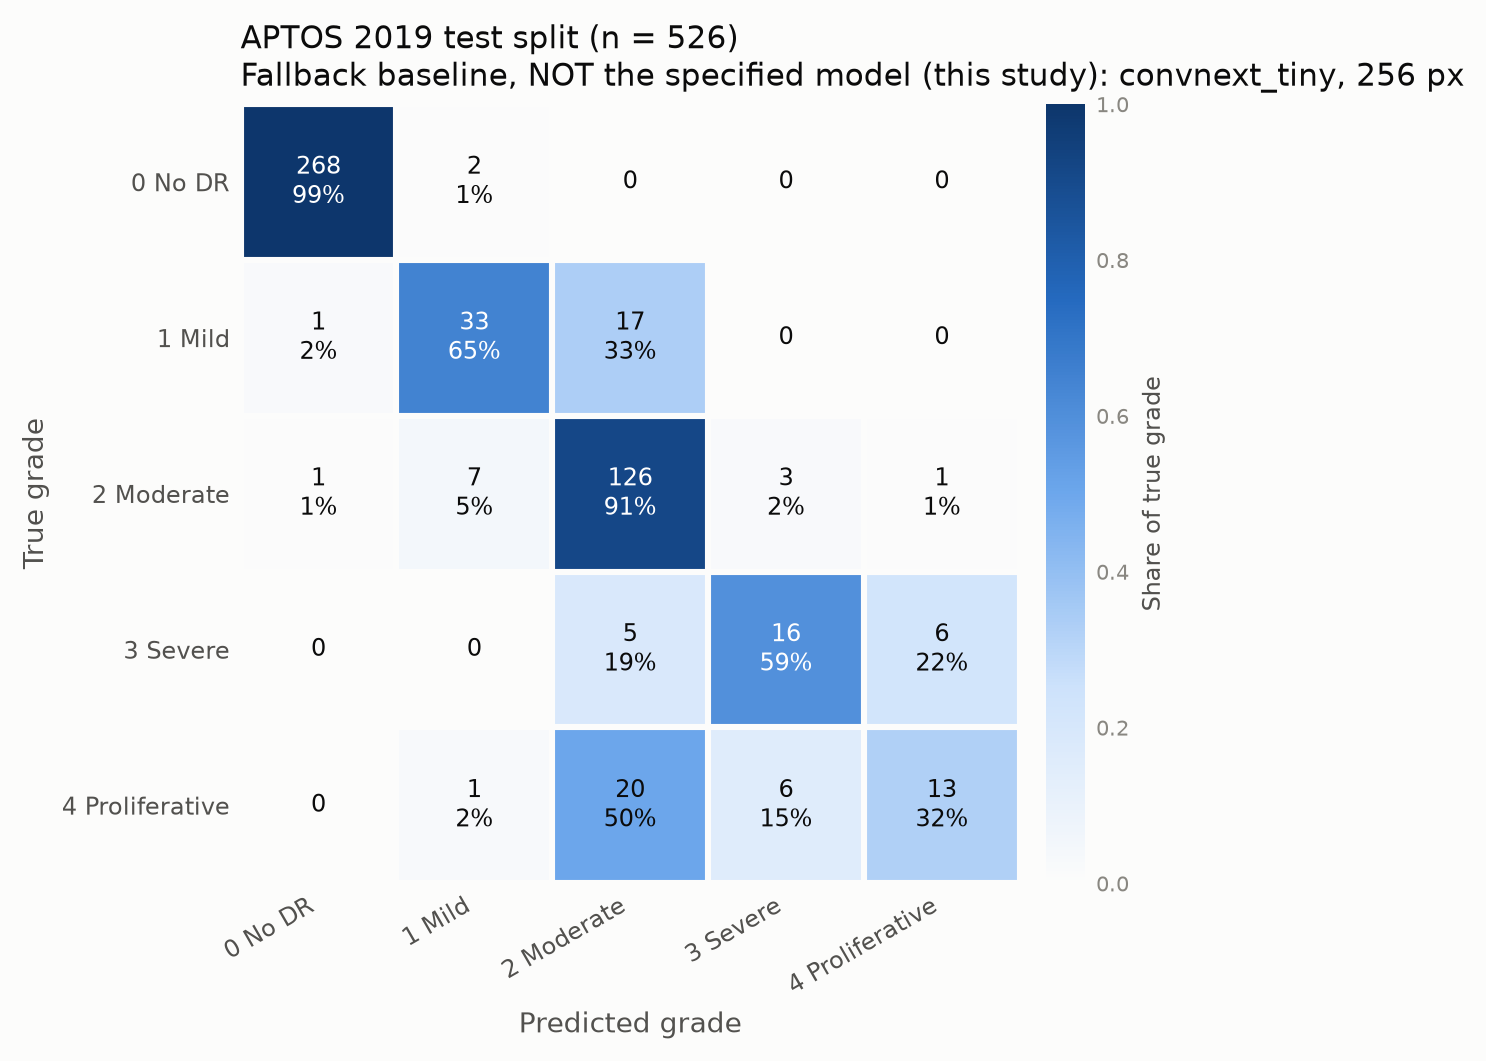

In [2]:
FIGS = RESULTS / "figures"
matrices = sorted(FIGS.glob("confusion_matrix_*.png")) if FIGS.is_dir() else []
if not matrices:
    print("No confusion matrix. To create: python -m xaidr.cli figures --run <run id>")
for path in matrices:
    display(Image(str(path), width=560))

In [3]:
panels = sorted(FIGS.glob("saliency_*.png")) if FIGS.is_dir() else []
if not panels:
    print("No saliency panels. To create: python -m xaidr.cli figures --run <run id> --gallery 1")
for path in panels:
    display(Image(str(path), width=900))

No saliency panels. To create: python -m xaidr.cli figures --run <run id> --gallery 1


In [4]:
per_image = [p for run in runs() for p in [run / "fidelity_per_image.csv"] if p.is_file()]
if not per_image:
    print("No per-image fidelity file: the IDRiD fidelity study has not been run (IDRiD is required).")
for path in per_image:
    frame = pd.read_csv(path)
    primary = frame[(frame["lesion"] == "any") & (frame["k_percent"] == frame["k_percent"].iloc[0])]
    for method, group in primary.groupby("method"):
        ranked = group.sort_values("iou")
        picks = ranked.iloc[[len(ranked) - 1, len(ranked) // 2, 0]].assign(case=["good", "average", "poor"])
        print(method); display(picks[["case", "image_id", "iou", "chance_iou", "max_iou", "pointing"]])

No per-image fidelity file: the IDRiD fidelity study has not been run (IDRiD is required).
